In [17]:
!pip install -q scikit-learn gradio

In [18]:
# ==========================================
# SCAMSHIELD - MULTILINGUAL SUPPORT
# ==========================================

SUPPORTED_LANGUAGES = {
    "English": "en",
    "Kannada": "kn",
    "Hindi": "hi",
    "Telugu": "te",
    "Tamil": "ta"
}

SCAM_WARNINGS = {
    "en": "Warning! This message may be a scam. Do not share OTPs or banking details.",
    "kn": "ಎಚ್ಚರಿಕೆ! ಈ ಸಂದೇಶ ವಂಚನೆಯಾಗಿರಬಹುದು. OTP ಅಥವಾ ಬ್ಯಾಂಕ್ ವಿವರಗಳನ್ನು ಹಂಚಿಕೊಳ್ಳಬೇಡಿ.",
    "hi": "चेतावनी! यह संदेश धोखाधड़ी हो सकता है। OTP या बैंक विवरण साझा न करें।",
    "te": "హెచ్చరిక! ఈ సందేశం మోసం కావచ్చు. OTP లేదా బ్యాంక్ వివరాలను పంచుకోవద్దు.",
    "ta": "எச்சரிக்கை! இந்த செய்தி மோசடியாக இருக்கலாம். OTP அல்லது வங்கி விவரங்களைப் பகிர வேண்டாம்."
}

def get_scam_warning(language="en"):
    return SCAM_WARNINGS.get(
        language,
        SCAM_WARNINGS["en"]
    )

def multilingual_scam_check(message, language="en"):
    result = predict_scam(message)

    warning = get_scam_warning(language)

    return {
        "message": message,
        "prediction": result,
        "warning": warning
    }

print("ScamShield Multilingual Support Ready!")
print(get_scam_warning("kn"))

ScamShield Multilingual Support Ready!
ಎಚ್ಚರಿಕೆ! ಈ ಸಂದೇಶ ವಂಚನೆಯಾಗಿರಬಹುದು. OTP ಅಥವಾ ಬ್ಯಾಂಕ್ ವಿವರಗಳನ್ನು ಹಂಚಿಕೊಳ್ಳಬೇಡಿ.


In [19]:
from IPython.display import display, HTML

voice_interface = """
<div style="padding:20px; border:2px solid #16a34a;
border-radius:15px; text-align:center;">

<h2>🛡️ ScamShield Voice Detection</h2>

<button onclick="startListening()"
style="padding:12px 22px; background:#16a34a;
color:white; border:0; border-radius:8px;">
🎤 Start Speaking
</button>

<p id="voice_status">Click to speak</p>
<textarea id="voice_text" rows="4"
style="width:95%; padding:10px;"
placeholder="Your spoken message will appear here"></textarea>

</div>

<script>
function startListening() {
    const SpeechRecognition =
        window.SpeechRecognition ||
        window.webkitSpeechRecognition;

    if (!SpeechRecognition) {
        document.getElementById("voice_status").innerText =
        "Speech recognition is not supported in this browser.";
        return;
    }

    const recognition = new SpeechRecognition();
    recognition.lang = "en-IN";
    recognition.interimResults = false;

    document.getElementById("voice_status").innerText =
    "Listening...";

    recognition.onresult = function(event) {
        document.getElementById("voice_text").value =
        event.results[0][0].transcript;

        document.getElementById("voice_status").innerText =
        "Voice captured successfully!";
    };

    recognition.onerror = function(event) {
        document.getElementById("voice_status").innerText =
        "Error: " + event.error;
    };

    recognition.start();
}
</script>
"""

display(HTML(voice_interface))

In [20]:
# ==================================================
# SCAMSHIELD - FAKE UPI COLLECT REQUEST DETECTION
# ==================================================

import re

def detect_fake_upi_request(message):

    text = message.lower()

    suspicious_patterns = {
        "Payment approval request": [
            r"approve.*payment",
            r"collect request",
            r"request.*money",
            r"pay.*to receive"
        ],
        "OTP or PIN request": [
            r"share.*otp",
            r"enter.*upi pin",
            r"share.*upi pin",
            r"tell.*otp"
        ],
        "Fake refund or reward": [
            r"claim.*refund",
            r"receive.*cashback",
            r"free.*reward",
            r"prize.*claim"
        ],
        "Urgency or threats": [
            r"account.*blocked",
            r"immediately",
            r"urgent.*payment",
            r"account.*suspended"
        ],
        "Suspicious payment link": [
            r"https?://\S+",
            r"bit\.ly/\S+",
            r"tinyurl\.com/\S+"
        ]
    }

    detected = []

    for category, patterns in suspicious_patterns.items():
        for pattern in patterns:
            if re.search(pattern, text):
                detected.append(category)
                break

    risk_score = min(len(detected) * 20, 100)

    if risk_score >= 60:
        risk_level = "HIGH RISK"
    elif risk_score >= 20:
        risk_level = "SUSPICIOUS"
    else:
        risk_level = "LOW RISK"

    if detected:
        warning = (
            "Do not approve unexpected payment requests. "
            "Never share your UPI PIN or OTP."
        )
    else:
        warning = (
            "No listed suspicious patterns detected. "
            "This does not guarantee the message is safe."
        )

    return {
        "Risk Level": risk_level,
        "Risk Score": risk_score,
        "Detected Warning Signs": detected,
        "Safety Advice": warning
    }


# Test ScamShield UPI Detection

sample_message = (
    "Your account has a cashback reward. "
    "Approve this collect request immediately."
)

result = detect_fake_upi_request(sample_message)

print("🛡️ SCAMSHIELD UPI SECURITY REPORT")
print("----------------------------------")

for key, value in result.items():
    print(f"{key}: {value}")

🛡️ SCAMSHIELD UPI SECURITY REPORT
----------------------------------
Risk Level: SUSPICIOUS
Risk Score: 40
Detected Warning Signs: ['Payment approval request', 'Urgency or threats']
Safety Advice: Do not approve unexpected payment requests. Never share your UPI PIN or OTP.


In [21]:
# ==================================================
# SCAMSHIELD - FRAUD AWARENESS DASHBOARD
# ==================================================

import matplotlib.pyplot as plt
from IPython.display import display, HTML, clear_output

# Store analysis history
if "scam_history" not in globals():
    scam_history = []

def analyse_and_save(message):
    result = detect_fake_upi_request(message)

    scam_history.append({
        "Message": message,
        "Risk Level": result["Risk Level"],
        "Risk Score": result["Risk Score"]
    })

    return result


def scamshield_dashboard():

    total = len(scam_history)

    high = sum(
        1 for item in scam_history
        if item["Risk Level"] == "HIGH RISK"
    )

    suspicious = sum(
        1 for item in scam_history
        if item["Risk Level"] == "SUSPICIOUS"
    )

    low = sum(
        1 for item in scam_history
        if item["Risk Level"] == "LOW RISK"
    )

    display(HTML("""
    <div style="background:#101827;color:white;
    padding:22px;border-radius:14px;text-align:center;">
        <h1>🛡️ ScamShield</h1>
        <h3>Fraud Awareness Dashboard</h3>
        <p>Your Digital Safety Command Center</p>
    </div>
    """))

    print("\n📊 SECURITY OVERVIEW")
    print("-----------------------------")
    print("Total Messages Analysed:", total)
    print("🔴 High Risk:", high)
    print("🟠 Suspicious:", suspicious)
    print("🟢 Low Risk:", low)

    if total > 0:
        labels = ["High Risk", "Suspicious", "Low Risk"]
        values = [high, suspicious, low]

        plt.figure(figsize=(7, 4))
        plt.pie(
            values,
            labels=labels,
            autopct="%1.1f%%",
            startangle=90
        )
        plt.title("ScamShield Risk Distribution")
        plt.show()

    print("\n📋 DETECTION HISTORY")

    if scam_history:
        for index, item in enumerate(scam_history, 1):
            print(f"\n{index}. {item['Message']}")
            print("Risk:", item["Risk Level"])
            print("Score:", item["Risk Score"])
    else:
        print("No messages analysed yet.")

    display(HTML("""
    <div style="background:#172554;color:white;
    padding:18px;border-radius:12px;margin-top:15px;">
        <h3>🔐 Cyber Safety Tips</h3>
        <ul>
        <li>Never share your OTP or UPI PIN.</li>
        <li>Verify unexpected payment requests.</li>
        <li>Never click suspicious payment links.</li>
        <li>Remember: Receiving money does not require entering your UPI PIN.</li>
        <li>Report suspected cyber fraud through official channels.</li>
        </ul>
    </div>
    """))


print("ScamShield Fraud Awareness Dashboard Ready!")

ScamShield Fraud Awareness Dashboard Ready!


In [22]:
# Add sample messages to dashboard history

analyse_and_save(
    "Your account has a cashback reward. Approve this collect request immediately."
)

analyse_and_save(
    "Share your OTP to receive your refund immediately."
)

analyse_and_save(
    "Hello, your meeting is scheduled for tomorrow."
)

print("Sample detection history added!")

Sample detection history added!



📊 SECURITY OVERVIEW
-----------------------------
Total Messages Analysed: 3
🔴 High Risk: 0
🟠 Suspicious: 2
🟢 Low Risk: 1


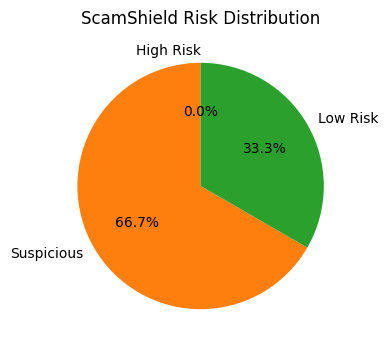


📋 DETECTION HISTORY

1. Your account has a cashback reward. Approve this collect request immediately.
Risk: SUSPICIOUS
Score: 40

2. Share your OTP to receive your refund immediately.
Risk: SUSPICIOUS
Score: 40

3. Hello, your meeting is scheduled for tomorrow.
Risk: LOW RISK
Score: 0


In [23]:
scamshield_dashboard()

In [24]:
print("Multilingual:", "multilingual_scam_check" in globals())
print("Voice:", "voice_interface" in globals())
print("UPI:", "detect_fake_upi_request" in globals())
print("Dashboard:", "scamshield_dashboard" in globals())
print("Original AI model:", "predict_scam" in globals())

Multilingual: True
Voice: True
UPI: True
Dashboard: True
Original AI model: False


In [25]:
import re
import gradio as gr

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Sample training dataset
# 1 = Scam, 0 = Legitimate

messages = [
    # Scam messages
    "Your bank account is blocked. Verify your OTP now",
    "Congratulations you won a lottery. Pay fee to claim prize",
    "Click this link to update your bank KYC immediately",
    "Share your UPI PIN to receive your cashback",
    "Your account will close today. Click this link",
    "Send your OTP to receive your refund",
    "You have won a free gift. Pay processing charges",
    "Install this app to unblock your bank account",
    "Your electricity connection will be disconnected. Pay now",
    "Approve this UPI collect request to receive money",
    "Your ATM card is blocked. Share your CVV",
    "Urgent payment required to avoid account suspension",
    "You have received a prize. Enter your bank details",
    "Download this remote access app for bank verification",
    "Click suspicious link to claim free rewards",
    "Send money first to receive your job offer",
    "Your parcel is held. Pay a small delivery fee here",
    "Share your password to verify your bank account",
    "Your KYC expired. Enter your details immediately",
    "Transfer money to unlock your account",

    # Legitimate messages
    "Your bank statement is ready for download",
    "Your salary has been credited to your account",
    "Your UPI payment of 250 rupees was successful",
    "Your electricity bill payment was successful",
    "Your account balance is available in the bank app",
    "Your debit card transaction was completed",
    "Your bank branch will remain closed on Sunday",
    "Your monthly statement is ready",
    "Never share your OTP or UPI PIN with anyone",
    "Your college fee payment was successful",
    "Your refund has been processed",
    "Your bank has received your complaint",
    "Your transaction receipt is available",
    "Your loan application status has been updated",
    "Your account received a deposit",
    "Your bank appointment is confirmed",
    "Your payment was declined. Contact your bank through its official app",
    "Your fixed deposit maturity date is approaching",
    "Your account service request is complete",
    "Your monthly bill is ready to view"
]

labels = [1] * 20 + [0] * 20

# Create and train machine learning model
model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(messages, labels)

# Suspicious patterns
rules = {
    "OTP or PIN request": r"\b(otp|upi pin|atm pin|cvv|password)\b",
    "Urgent pressure": r"\b(urgent|immediately|today|blocked|suspended)\b",
    "Suspicious link": r"(https?://|bit\.ly|tinyurl|click this link)",
    "Prize or reward offer": r"\b(lottery|won a prize|free gift|cashback)\b",
    "Payment demand": r"\b(processing fee|pay now|transfer money|send money)\b",
    "Remote access request": r"\b(anydesk|remote access|screen sharing)\b"
}

def detect_scam(message):

    if not message.strip():
        return "Please enter a message.", "No analysis available."

    probability = model.predict_proba([message])[0][1]

    reasons = []

    for reason, pattern in rules.items():
        if re.search(pattern, message, re.IGNORECASE):
            reasons.append(reason)

    # Combined prototype risk score
    score = int(probability * 65 + min(len(reasons), 3) * 12)
    score = min(score, 100)

    if score >= 65:
        result = "HIGH RISK"
    elif score >= 35:
        result = "MEDIUM RISK"
    else:
        result = "LOW RISK"

    explanation = (
        f"Risk score: {score}/100\n"
        f"Result: {result}\n\n"
        f"ML model scam score: {probability * 100:.1f}%\n\n"
        "Warning signs:\n"
    )

    if reasons:
        explanation += "\n".join(
            "- " + reason for reason in reasons
        )
    else:
        explanation += "- No listed warning signs detected."

    explanation += (
        "\n\nNote: This is an experimental demo. "
        "A low score does not guarantee safety. "
        "Always verify payments independently."
    )

    return result, explanation


# Create web interface
demo = gr.Interface(
    fn=detect_scam,
    inputs=gr.Textbox(
        lines=5,
        label="Enter SMS / WhatsApp message",
        placeholder="Paste a message to check..."
    ),
    outputs=[
        gr.Textbox(label="Fraud Risk"),
        gr.Textbox(label="AI Analysis")
    ],
    title="ScamShield - AI Scam Detector",
    description="Check suspicious financial messages using AI."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0f3ed9ae54ad8e17d8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
